# 6. Counting statistics

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 3 and 5

**Reading:** Taylor, ch. 3.2 and 11 · Bevington & Robinson, ch. 2.2 ·
Fornasini, ch. 1.5 and 6.4 · Knoll, *Radiation Detection and Measurement*,
ch. 3

Many measurements are counts: decays registered by a detector, photons on
a pixel, cells in a field of view, events in a time window. Counting has a
special place in error analysis because the uncertainty is not estimated
from repeated readings but follows from the nature of the process itself.
A single count $N$ comes with its own uncertainty, $\sqrt N$.

This chapter

1. explains when the $\sqrt N$ rule holds, and how to check that it does;
2. treats background subtraction and the best division of counting time
   between source and background;
3. shows where $\sqrt N$ fails, at small counts, and what to use instead;
4. corrects for the dead time of a counter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(118)

## 6.1 The square-root rule

If events occur independently of one another at a constant average rate
$R$, the number $N$ counted in a time $t$ follows the Poisson distribution
with mean $\mu = Rt$ and variance $\mu$ (Section 5.2). A single count is
the best estimate of $\mu$, and its standard uncertainty is

$$ u_N = \sqrt{\mu} \approx \sqrt N . $$

The *relative* uncertainty $1/\sqrt N$ depends only on the number of
counts, not on how long it took to collect them: 100 counts give 10 %,
10 000 counts give 1 %. A rate $R = N/t$, with $t$ known precisely, has
$u_R = \sqrt N/t$.

**Checking the assumption.** The rule rests on two assumptions: the events
are independent and the rate is constant. A source whose intensity
fluctuates, a detector whose efficiency drifts, or a process in which
events come in clusters all produce counts that scatter *more* than
Poisson; dead time (Section 6.4) makes them scatter *less*. The test is
simple: record many counts in equal intervals and compare their variance
with their mean. For Poisson data the **index of dispersion**

$$ D = \frac{(n-1)\,s^2}{\bar N} $$

follows approximately a $\chi^2$ distribution with $n-1$ degrees of freedom
($n$ being the number of intervals).

In [2]:
def dispersion_test(counts):
    n = counts.size
    D = (n - 1) * counts.var(ddof=1) / counts.mean()
    return D / (n - 1), stats.chi2.sf(D, n - 1)

steady = rng.poisson(50.0, 40)                                  # constant rate
drifting = rng.poisson(50.0 * (1 + 0.15 * rng.normal(size=40)))   # intensity fluctuates by 15 %
for name, c in (("steady source", steady), ("fluctuating source", drifting)):
    ratio, p = dispersion_test(c)
    print(f"{name:20s}: mean {c.mean():5.1f}, variance {c.var(ddof=1):6.1f}, "
          f"variance/mean = {ratio:.2f}, p = {p:.3f}")

steady source       : mean  51.8, variance   50.6, variance/mean = 0.98, p = 0.511
fluctuating source  : mean  50.8, variance  141.1, variance/mean = 2.78, p = 0.000


For the steady source, variance and mean agree. For the fluctuating one,
the variance is nearly three times the mean (a 15 % fluctuation of a mean
of 50 adds $(0.15 \times 50)^2 \approx 56$ to the Poisson variance of 50)
and the test rejects the Poisson hypothesis decisively. In that case $\sqrt N$ would understate the
uncertainty of a count, and the scatter of repeated counts (Chapter 4)
must be used instead.

## 6.2 Background subtraction

A weak source is measured on top of a background (cosmic rays, natural
radioactivity, dark counts). One counts $G$ events with the source in place
for a time $t_g$ ("gross"), and $B$ events without it for a time $t_b$. The
net source rate is

$$ R_s = \frac{G}{t_g} - \frac{B}{t_b} , \qquad
   u_{R_s}^2 = \frac{G}{t_g^2} + \frac{B}{t_b^2} , $$

by the propagation law for a difference of independent counts. Note that
the uncertainties *add*, although the counts are subtracted: subtracting a
background always costs precision.

**How to divide the time.** With a fixed total time $T = t_g + t_b$, how
much should be spent on the background? Writing the expected counts as
$G = R_g t_g$ and $B = R_b t_b$, the variance is
$R_g/t_g + R_b/t_b$. Minimising it subject to $t_g + t_b = T$ (set the
derivative of $R_g/t_g + R_b/(T - t_g)$ to zero) gives

$$ \frac{t_g}{t_b} = \sqrt{\frac{R_g}{R_b}} . $$

A strong source needs relatively little background time; for a source
barely above background, the time should be split almost equally.

In [3]:
R_s_true, R_b = 2.0, 8.0          # counts per second: weak source on a larger background
R_g = R_s_true + R_b
T = 3600.0                        # one hour in total
f = np.linspace(0.05, 0.95, 181)  # fraction of the time spent on the gross measurement
u_net = np.sqrt(R_g / (f * T) + R_b / ((1 - f) * T))
f_opt = 1 / (1 + np.sqrt(R_b / R_g))
print(f"optimum fraction on the gross count: {f_opt:.3f}  (t_g/t_b = sqrt(R_g/R_b) = {np.sqrt(R_g / R_b):.3f})")
print(f"net-rate uncertainty: optimum {np.sqrt(R_g / (f_opt * T) + R_b / ((1 - f_opt) * T)):.4f} /s, "
      f"equal split {np.sqrt(R_g / (0.5 * T) + R_b / (0.5 * T)):.4f} /s, "
      f"90/10 split {np.sqrt(R_g / (0.9 * T) + R_b / (0.1 * T)):.4f} /s")

# check by simulation: many one-hour experiments at the optimum split
t_g, t_b = f_opt * T, (1 - f_opt) * T
G = rng.poisson(R_g * t_g, 100_000); B = rng.poisson(R_b * t_b, 100_000)
net = G / t_g - B / t_b
print(f"simulated: mean net rate {net.mean():.4f} /s (true {R_s_true}), standard deviation {net.std():.4f} /s")

optimum fraction on the gross count: 0.528  (t_g/t_b = sqrt(R_g/R_b) = 1.118)
net-rate uncertainty: optimum 0.0998 /s, equal split 0.1000 /s, 90/10 split 0.1591 /s
simulated: mean net rate 2.0000 /s (true 2.0), standard deviation 0.0997 /s


The optimum is broad (panel (c) of the figure below): here even an equal
split is practically as good. A badly unbalanced split is not. Spending only
a tenth of the time on the background raises the variance by a factor of
2.5, as much as cutting the total measuring time by that factor.

## 6.3 Small counts

The $\sqrt N$ rule is an approximation that fails when $N$ is small. If no
event is counted, $N = 0 \pm 0$ is plainly wrong: a source of mean 2 would
give zero counts 13.5 % of the time. More generally the Poisson
distribution is skewed for small $\mu$, and $N \pm \sqrt N$ is neither the
right width nor the right shape.

**Exact intervals.** The classical (Garwood) interval for a Poisson mean,
given an observed count $N$, is the set of means $\mu$ for which $N$ is not
in either tail of the distribution. It can be written in terms of the
$\chi^2$ quantiles,

$$ \mu_\text{low} = \tfrac12\chi^2_{\alpha/2}(2N), \qquad \mu_\text{up} = \tfrac12\chi^2_{1-\alpha/2}(2N+2) , $$

for a confidence level $1 - \alpha$, and is implemented in
`ep.poisson_interval`. For $N = 0$ the 90 % one-sided upper limit is
$\mu < 2.30$, the number behind statements such as "no events observed;
the rate is below 2.3 per counting period at 90 % confidence".

In [4]:
for N in (0, 1, 3, 10, 100):
    lo, hi = ep.poisson_interval(N)
    print(f"N = {N:3d}:  sqrt rule [{N - np.sqrt(N):6.2f}, {N + np.sqrt(N):6.2f}]   exact 68.3 % [{float(lo):6.2f}, {float(hi):6.2f}]")
print(f"N = 0: 90 % one-sided upper limit = {-np.log(0.10):.3f}")

mu_grid = np.linspace(0.2, 30, 300)
kk = np.arange(0, 120)
lo_k, hi_k = ep.poisson_interval(kk)
cov_sqrt, cov_exact = [], []
for mu in mu_grid:
    pk = stats.poisson.pmf(kk, mu)
    cov_sqrt.append(pk[np.abs(kk - mu) <= np.sqrt(kk)].sum())
    cov_exact.append(pk[(lo_k <= mu) & (mu <= hi_k)].sum())
cov_sqrt, cov_exact = np.array(cov_sqrt), np.array(cov_exact)
print(f"\ncoverage of N +/- sqrt(N): {cov_sqrt[mu_grid < 3].min():.2f} to {cov_sqrt[mu_grid < 3].max():.2f} for mu < 3, "
      f"{cov_sqrt[mu_grid > 20].min():.2f} to {cov_sqrt[mu_grid > 20].max():.2f} for mu > 20")
print(f"coverage of the exact interval: never below {cov_exact.min():.3f}")

N =   0:  sqrt rule [  0.00,   0.00]   exact 68.3 % [  0.00,   1.84]
N =   1:  sqrt rule [  0.00,   2.00]   exact 68.3 % [  0.17,   3.30]
N =   3:  sqrt rule [  1.27,   4.73]   exact 68.3 % [  1.37,   5.92]
N =  10:  sqrt rule [  6.84,  13.16]   exact 68.3 % [  6.89,  14.27]
N = 100:  sqrt rule [ 90.00, 110.00]   exact 68.3 % [ 90.02, 111.03]
N = 0: 90 % one-sided upper limit = 2.303

coverage of N +/- sqrt(N): 0.16 to 0.73 for mu < 3, 0.63 to 0.72 for mu > 20
coverage of the exact interval: never below 0.685


Below a mean of a few counts the interval $N \pm \sqrt N$ can miss the true
mean far more often than the nominal 32 %; for large counts its coverage
fluctuates around 68 %. The exact interval never covers less than the
nominal level, at the price of being somewhat conservative (panel (b)).
The discreteness of counts makes exact coverage impossible at every $\mu$,
and statisticians have proposed several refinements, notably the unified
intervals of Feldman and Cousins (1998), which also handle a known
background properly.

Small counts cause trouble beyond intervals. Using $\sqrt{N_i}$ as the
uncertainty of each bin of a histogram in a least-squares fit biases the
result, because low fluctuations get small error bars and high weight.
Chapter 15 shows how a likelihood fit avoids this.

## 6.4 Dead time

After registering an event, a counter is blind for a short **dead time**
$\tau$. In the simplest (non-paralysable) model, events arriving during that
time are lost without extending it. If the true rate is $n$ and the
recorded rate $m$, the counter is dead for a fraction $m\tau$ of the time,
so $m = n(1 - m\tau)$ and

$$ n = \frac{m}{1 - m\tau} . $$

The correction is negligible when $m\tau \ll 1$ and large when $m\tau$
approaches 1. Its uncertainty has two parts: the counting uncertainty of $m$,
amplified by $\mathrm dn/\mathrm dm = 1/(1 - m\tau)^2$, and the
uncertainty of $\tau$ itself, a systematic contribution common to all
measurements made with the same counter.

In [5]:
tau, u_tau = 2.0e-6, 0.2e-6           # dead time 2.0 +/- 0.2 microseconds
t_count = 10.0
for n_true in (1e3, 3e4, 1.5e5):
    m_exp = n_true / (1 + n_true * tau)
    M = rng.poisson(m_exp * t_count)
    m = M / t_count
    nhat, u_tot = ep.propagate(lambda m, tau: m / (1 - m * tau), [m, tau], [np.sqrt(M) / t_count, u_tau])
    _, u_count = ep.propagate(lambda m, tau: m / (1 - m * tau), [m, tau], [np.sqrt(M) / t_count, 0.0])
    print(f"true {n_true:8.0f}/s: recorded {m:9.0f}/s (expected loss {1 - m_exp / n_true:5.1%}), corrected "
          f"{ep.format_result(nhat, u_tot)} /s  [counting {u_count:.0f}, dead time {np.sqrt(u_tot**2 - u_count**2):.0f}]")

true     1000/s: recorded       989/s (expected loss  0.2%), corrected 991 ± 10 /s  [counting 10, dead time 0]
true    30000/s: recorded     28421/s (expected loss  5.7%), corrected 30130 ± 190 /s  [counting 60, dead time 182]
true   150000/s: recorded    115391/s (expected loss 23.1%), corrected (1.500 ± 0.045) × 10^5 /s  [counting 182, dead time 4501]


At low rates the correction and its uncertainty are negligible. At the
highest rate, where almost a quarter of the events are lost, the 10 % uncertainty
of the dead time contributes far more than counting statistics. Dead time
also changes the statistics themselves: a counter with dead time records
events that are more regularly spaced than Poisson events, so the variance
of the counts is *less* than their mean.

In [6]:
# variance-to-mean ratio of counts with a non-paralysable dead time
n_true, t_win = 1.5e5, 1e-3
arrivals = np.cumsum(rng.exponential(1 / n_true, 2_000_000))
kept = [arrivals[0]]
for t_ev in arrivals[1:]:
    if t_ev - kept[-1] >= tau:
        kept.append(t_ev)
kept = np.array(kept)
edges = np.arange(0, kept[-1], t_win)
counts_dead = np.histogram(kept, edges)[0]
counts_true = np.histogram(arrivals, edges)[0]
print(f"variance/mean of counts per 1 ms: without dead time {counts_true.var() / counts_true.mean():.3f}, "
      f"recorded {counts_dead.var() / counts_dead.mean():.3f}  (expected (1 - m tau)^2 = {(1 - counts_dead.mean() / t_win * tau)**2:.3f})")

variance/mean of counts per 1 ms: without dead time 1.006, recorded 0.590  (expected (1 - m tau)^2 = 0.591)


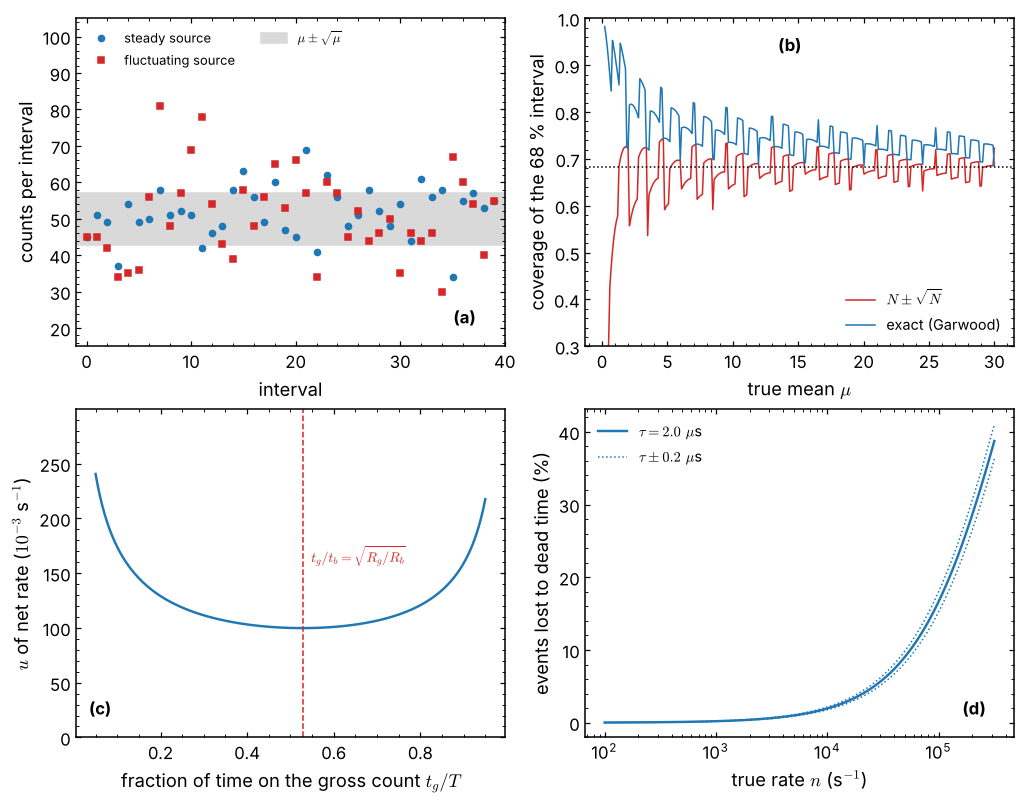

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
ax.plot(steady, "o", color="C0", ms=4, label="steady source")
ax.plot(drifting, "s", color="C3", ms=4, label="fluctuating source")
ax.fill_between([-1, 40], 50 - np.sqrt(50), 50 + np.sqrt(50), color="0.85", label=r"$\mu \pm \sqrt{\mu}$")
ax.set_xlim(-1, 40); ax.set_xlabel("interval"); ax.set_ylabel("counts per interval")
ax.legend(loc="upper left", fontsize=8.5, ncol=2); ax.set_ylim(15, 105); ep.panel_label(ax, "(a)", x=0.88, y=0.12)

ax = axes[0, 1]
ax.plot(mu_grid, cov_sqrt, "C3", lw=1, label=r"$N \pm \sqrt{N}$")
ax.plot(mu_grid, cov_exact, "C0", lw=1, label="exact (Garwood)")
ax.axhline(0.6827, color="k", ls=":", lw=1)
ax.set_xlabel(r"true mean $\mu$"); ax.set_ylabel("coverage of the 68 % interval")
ax.set_ylim(0.3, 1.0); ax.legend(loc="lower right"); ep.panel_label(ax, "(b)", x=0.45)

ax = axes[1, 0]
ax.plot(f, 1e3 * u_net, "C0")
ax.axvline(f_opt, color="C3", ls="--", lw=1)
ax.text(f_opt + 0.02, 1e3 * u_net.min() * 1.6, r"$t_g/t_b = \sqrt{R_g/R_b}$", fontsize=9, color="C3")
ax.set_xlabel(r"fraction of time on the gross count $t_g/T$"); ax.set_ylabel(r"$u$ of net rate ($10^{-3}$ s$^{-1}$)")
ax.set_ylim(0, 3 * 1e3 * u_net.min()); ep.panel_label(ax, "(c)", y=0.12)

ax = axes[1, 1]
rr = np.logspace(2, 5.5, 200)
mm = rr / (1 + rr * tau)
ax.semilogx(rr, 100 * (1 - mm / rr), "C0", label=r"$\tau = 2.0\ \mu$s")
ax.semilogx(rr, 100 * (1 - (rr / (1 + rr * 1.8e-6)) / rr), "C0:", lw=1)
ax.semilogx(rr, 100 * (1 - (rr / (1 + rr * 2.2e-6)) / rr), "C0:", lw=1, label=r"$\tau \pm 0.2\ \mu$s")
ax.set_xlabel(r"true rate $n$ (s$^{-1}$)"); ax.set_ylabel("events lost to dead time (%)")
ax.legend(loc="upper left"); ep.panel_label(ax, "(d)", x=0.88, y=0.12)
plt.show()

**(a)** Counts in 40 equal intervals from a steady and from a fluctuating
source; the band is the Poisson expectation. **(b)** Coverage of the
$\sqrt N$ interval and of the exact interval as a function of the true
mean. **(c)** Uncertainty of a net rate against the share of a fixed time
spent on the gross count. **(d)** Fraction of events lost for a dead time
of 2.0 ± 0.2 µs.

## Summary

* For independent events at a constant rate, a count $N$ has uncertainty
  $\sqrt N$; check the assumption with the variance-to-mean ratio.
* In background subtraction, uncertainties add; divide a fixed time in the
  ratio $t_g/t_b = \sqrt{R_g/R_b}$.
* For small counts use exact Poisson intervals, not $N \pm \sqrt N$; a count of
  zero means an upper limit (2.3 at 90 %).
* Correct for dead time, and include its uncertainty, which is systematic
  and dominates at high rates.

## References

* G. F. Knoll, *Radiation Detection and Measurement*, 4th ed. (Wiley, 2010),
  ch. 3.
* F. Garwood, "Fiducial limits for the Poisson distribution", *Biometrika*
  **28**, 437 (1936).
* G. J. Feldman and R. D. Cousins, "Unified approach to the classical
  statistical analysis of small signals", *Phys. Rev. D* **57**, 3873 (1998).

## Exercises

1. A Geiger counter records 412 counts in 5 minutes with a sample and 125
   counts in 5 minutes without it. Find the net rate and its uncertainty.
   How should the next 10 minutes be divided to improve it most?
2. Show that minimising $R_g/t_g + R_b/t_b$ at fixed $t_g + t_b$ gives
   $t_g/t_b = \sqrt{R_g/R_b}$.
3. How many counts are needed for a 1 % measurement of a rate? How long
   does that take at 3 counts per second?
4. Compute the coverage of $N \pm \sqrt{N+1}$ as a function of $\mu$ and
   compare it with panel (b). Is it a useful improvement?
5. For a *paralysable* counter (every event, recorded or not, restarts the
   dead time), $m = n e^{-n\tau}$. Show that the recorded rate has a maximum
   and explain why a high measured rate can then correspond to two true
   rates.

---

**Previous:** [5. Probability distributions and the central limit theorem](05_probability_distributions.ipynb) &nbsp;·&nbsp; **Next:** [7. Estimators and maximum likelihood](07_estimators_and_maximum_likelihood.ipynb)